# 🏆 Notebook 05: Ensemble Architectures & Final Evaluation
## *PRML Capstone: Hard vs Soft Voting vs Individual Base Estimators*

---
### 🎯 Objectives
1. **Ensemble Architecture**: Combine diverse base classifiers (Kernel, Tree, Instance-based) into **Hard Voting** (majority rule) and **Soft Voting** (argmax probability sum).
2. **Out-of-Sample Evaluation**: Execute final test evaluation on unseen test partition (2,947 samples).
3. **Metrics Evaluation**: Compute Accuracy, Macro Precision, Macro Recall, Macro F1, and full Confusion Matrices.
4. **Deliverable Generation**: Generate final publication figures for presentation slide deck.

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore')
os.makedirs('../models', exist_ok=True)
os.makedirs('../presentation', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

# Load clean partitions
X_train, y_train, X_test, y_test = joblib.load('../data/processed_data.pkl')
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Ingested train samples: {len(X_train_scaled)}, test samples: {len(X_test_scaled)}")

Ingested train samples: 7352, test samples: 2947


## 1️⃣ Ensemble Formation (Hard vs Soft Voting)

In [2]:
# Instantiate top diverse base models
clf_svm = SVC(kernel='rbf', C=10.0, probability=True, random_state=42)
clf_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf_knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
clf_ada = AdaBoostClassifier(n_estimators=100, random_state=42)

estimators = [
    ('svm', clf_svm),
    ('rf', clf_rf),
    ('knn', clf_knn),
    ('ada', clf_ada)
]

# Construct Ensembles
hard_voting = VotingClassifier(estimators=estimators, voting='hard')
soft_voting = VotingClassifier(estimators=estimators, voting='soft')

all_candidate_models = {
    'SVM (RBF Kernel)': clf_svm,
    'Random Forest': clf_rf,
    'Weighted KNN (k=5)': clf_knn,
    'AdaBoost': clf_ada,
    'Hard Voting Ensemble': hard_voting,
    'Soft Voting Ensemble': soft_voting
}

print("Training all candidate models and ensembles on full training set...")
test_metrics = {}

for name, model in all_candidate_models.items():
    model.fit(X_train_scaled, y_train_enc)
    preds = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test_enc, preds)
    prec = precision_score(y_test_enc, preds, average='macro')
    rec = recall_score(y_test_enc, preds, average='macro')
    f1 = f1_score(y_test_enc, preds, average='macro')
    
    test_metrics[name] = {
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2)
    }
    print(f"{name:22s} -> Test Acc: {acc*100:.2f}% | F1: {f1*100:.2f}%")

final_comparison_table = pd.DataFrame(test_metrics).T.sort_values(by='Accuracy (%)', ascending=False)
print("\n" + "=" * 65)
print("FINAL TEST SET BENCHMARK REPORT (2,947 UNSEEN SAMPLES)")
print("=" * 65)
print(final_comparison_table)

Training all candidate models and ensembles on full training set...


SVM (RBF Kernel)       -> Test Acc: 95.39% | F1: 95.30%


Random Forest          -> Test Acc: 92.70% | F1: 92.50%
Weighted KNN (k=5)     -> Test Acc: 88.56% | F1: 88.26%


AdaBoost               -> Test Acc: 62.98% | F1: 52.18%


Hard Voting Ensemble   -> Test Acc: 94.54% | F1: 94.38%


Soft Voting Ensemble   -> Test Acc: 94.94% | F1: 94.78%

FINAL TEST SET BENCHMARK REPORT (2,947 UNSEEN SAMPLES)
                      Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
SVM (RBF Kernel)             95.39          95.55       95.21         95.30
Soft Voting Ensemble         94.94          95.16       94.65         94.78
Hard Voting Ensemble         94.54          94.65       94.27         94.38
Random Forest                92.70          92.80       92.38         92.50
Weighted KNN (k=5)           88.56          89.43       88.06         88.26
AdaBoost                     62.98          63.64       62.66         52.18


## 2️⃣ Performance Benchmark Visualization

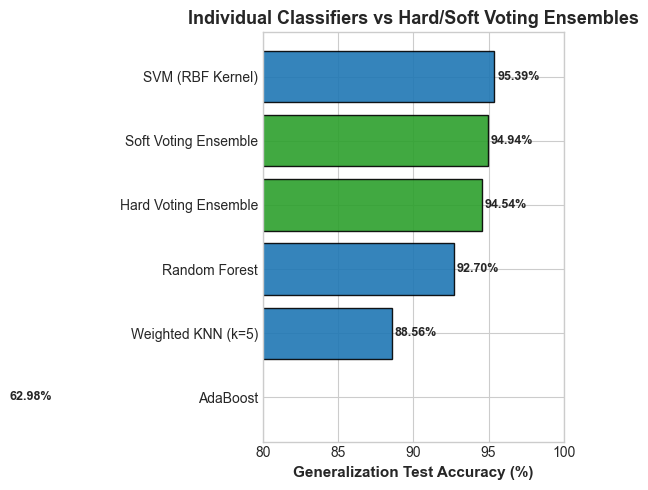

In [3]:
plt.figure(figsize=(10, 5))
colors = ['#2ca02c' if 'Voting' in k else '#1f77b4' for k in final_comparison_table.index]
bars = plt.barh(final_comparison_table.index[::-1], final_comparison_table['Accuracy (%)'][::-1], 
                color=colors[::-1], edgecolor='black', alpha=0.9)

plt.xlim(80, 100)
plt.xlabel('Generalization Test Accuracy (%)', fontweight='bold', fontsize=11)
plt.title('Individual Classifiers vs Hard/Soft Voting Ensembles', fontweight='bold', fontsize=13)
for b in bars:
    w = b.get_width()
    plt.text(w + 0.2, b.get_y() + b.get_height()/2, f"{w:.2f}%", va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('../presentation/13_final_ensemble_benchmark.png', dpi=200)
plt.show()

## 3️⃣ Detailed Classification Report for Champion Model

🏆 CHAMPION ARCHITECTURE: SVM (RBF Kernel)
                    precision    recall  f1-score   support

            LAYING       0.99      1.00      1.00       537
           SITTING       0.97      0.88      0.92       491
          STANDING       0.90      0.97      0.94       532
           WALKING       0.96      0.98      0.97       496
WALKING_DOWNSTAIRS       0.98      0.92      0.95       420
  WALKING_UPSTAIRS       0.94      0.97      0.95       471

          accuracy                           0.95      2947
         macro avg       0.96      0.95      0.95      2947
      weighted avg       0.95      0.95      0.95      2947



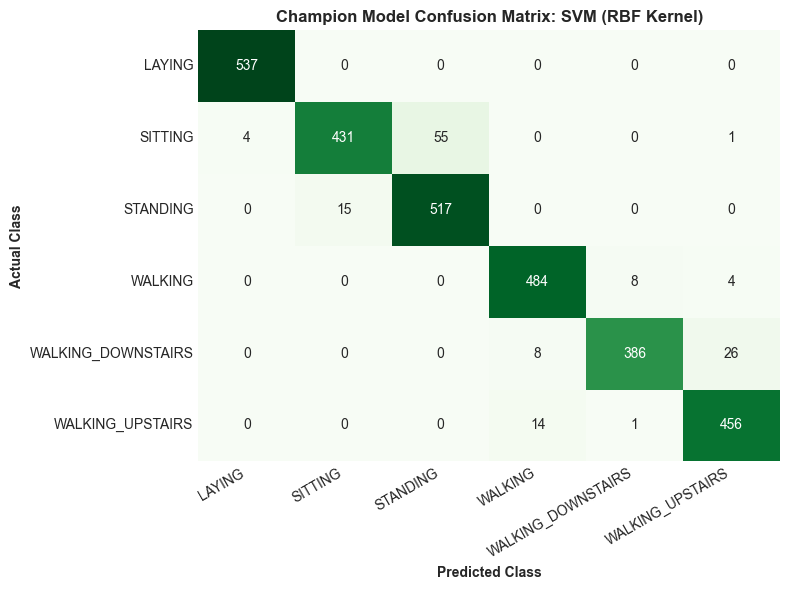

✅ Pipeline complete! All artifacts saved to ../models/final_evaluation_results.pkl


In [4]:
champion_name = final_comparison_table.index[0]
champion_model = all_candidate_models[champion_name]
y_champ_pred = champion_model.predict(X_test_scaled)

print(f"🏆 CHAMPION ARCHITECTURE: {champion_name}")
print(classification_report(y_test_enc, y_champ_pred, target_names=le.classes_))

# Confusion Matrix for Champion
cm = confusion_matrix(y_test_enc, y_champ_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Champion Model Confusion Matrix: {champion_name}', fontweight='bold')
plt.xlabel('Predicted Class', fontweight='bold')
plt.ylabel('Actual Class', fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../presentation/14_champion_confusion_matrix.png', dpi=200)
plt.show()

# Final Persistence for Streamlit & Demo Deployment
joblib.dump({
    'champion_model': champion_model,
    'champion_name': champion_name,
    'final_table': final_comparison_table,
    'scaler': scaler,
    'label_encoder': le,
    'models': all_candidate_models
}, '../models/final_evaluation_results.pkl')

print("✅ Pipeline complete! All artifacts saved to ../models/final_evaluation_results.pkl")